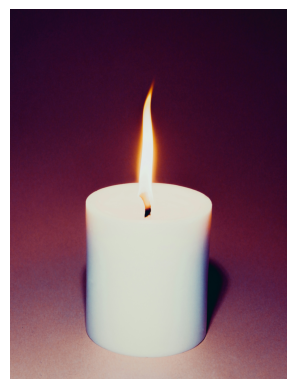

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
img = cv2.imread("99.jpg")
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

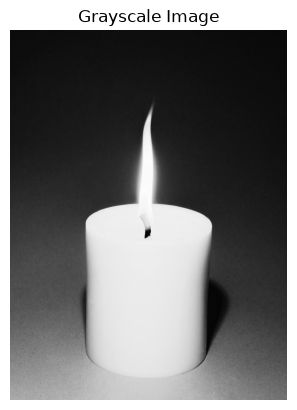

In [2]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

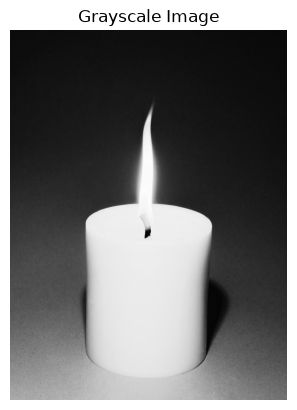

In [3]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

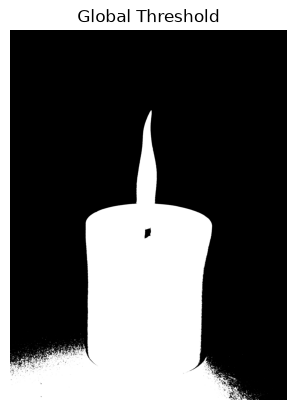

In [4]:
_, thresh = cv2.threshold(
 gray,
 127,
 255,
 cv2.THRESH_BINARY
)
plt.imshow(thresh, cmap="gray")
plt.title("Global Threshold")
plt.axis("off")
plt.show()


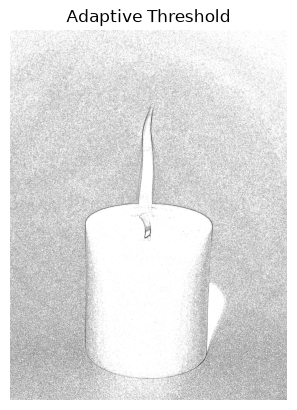

In [5]:
adaptive = cv2.adaptiveThreshold(
 gray,
 255,
 cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
 cv2.THRESH_BINARY,
 11,
 2
)
plt.imshow(adaptive, cmap="gray")
plt.title("Adaptive Threshold")
plt.axis("off")
plt.show()


In [6]:
kernel = np.ones((5, 5), np.uint8)
print(kernel)

[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


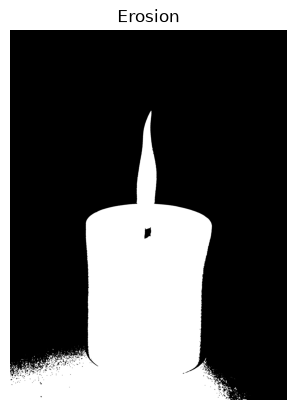

In [7]:
erosion = cv2.erode(
 thresh,
 kernel,
 iterations=1
)
plt.imshow(erosion, cmap="gray")
plt.title("Erosion")
plt.axis("off")
plt.show()

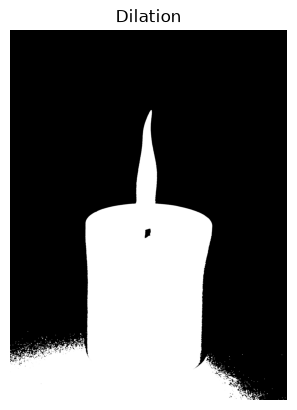

In [8]:
dilation = cv2.dilate(
 thresh,
 kernel,
 iterations=1
)
plt.imshow(dilation, cmap="gray")
plt.title("Dilation")
plt.axis("off")
plt.show()


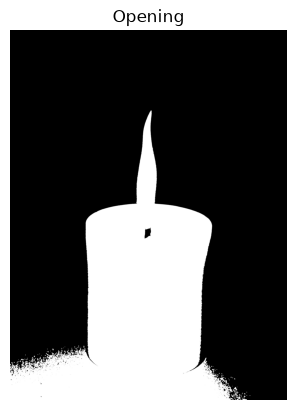

In [9]:
opening = cv2.morphologyEx(
 thresh,
 cv2.MORPH_OPEN,
 kernel
)
plt.imshow(opening, cmap="gray")
plt.title("Opening")
plt.axis("off")
plt.show()

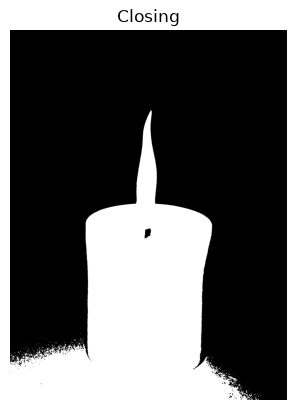

In [10]:
closing = cv2.morphologyEx(
 thresh,
 cv2.MORPH_CLOSE,
 kernel
)
plt.imshow(closing, cmap="gray")
plt.title("Closing")
plt.axis("off")
plt.show()

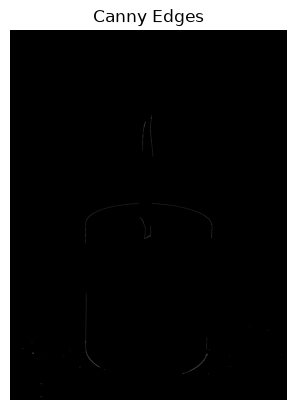

In [11]:
edges = cv2.Canny(
 gray,
 100,
 200
)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edges")
plt.axis("off")
plt.show()

In [12]:
contours, _ = cv2.findContours(
 thresh,
 cv2.RETR_EXTERNAL,
 cv2.CHAIN_APPROX_SIMPLE
)
print("Total Contours:", len(contours))

Total Contours: 3172


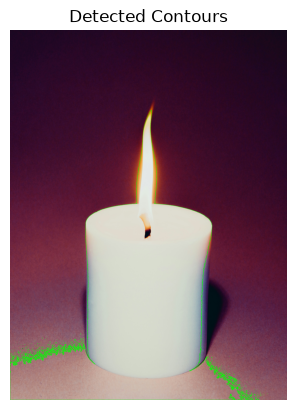

In [13]:
output = img.copy()
cv2.drawContours(
 output,
 contours,
 -1,
 (0, 255, 0),
 2
)
output_rgb = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)
plt.imshow(output_rgb)
plt.title("Detected Contours")
plt.axis("off")
plt.show()


In [14]:
print("Total Objects Detected:", len(contours))


Total Objects Detected: 3172


In [15]:
for i, contour in enumerate(contours):
 area = cv2.contourArea(contour)
 x, y, w, h = cv2.boundingRect(contour)
 print("Object:", i + 1)
 print("Area:", area, "square pixels")
 print("Width:", w, "pixels")
 print("Height:", h, "pixels")
 print("----------------")

Object: 1
Area: 0.0 square pixels
Width: 1 pixels
Height: 1 pixels
----------------
Object: 2
Area: 0.0 square pixels
Width: 1 pixels
Height: 1 pixels
----------------
Object: 3
Area: 0.0 square pixels
Width: 1 pixels
Height: 1 pixels
----------------
Object: 4
Area: 0.0 square pixels
Width: 2 pixels
Height: 1 pixels
----------------
Object: 5
Area: 0.0 square pixels
Width: 1 pixels
Height: 1 pixels
----------------
Object: 6
Area: 1.0 square pixels
Width: 2 pixels
Height: 2 pixels
----------------
Object: 7
Area: 0.0 square pixels
Width: 1 pixels
Height: 1 pixels
----------------
Object: 8
Area: 0.0 square pixels
Width: 1 pixels
Height: 2 pixels
----------------
Object: 9
Area: 0.0 square pixels
Width: 2 pixels
Height: 1 pixels
----------------
Object: 10
Area: 0.0 square pixels
Width: 1 pixels
Height: 1 pixels
----------------
Object: 11
Area: 0.0 square pixels
Width: 2 pixels
Height: 1 pixels
----------------
Object: 12
Area: 0.0 square pixels
Width: 1 pixels
Height: 1 pixels
------

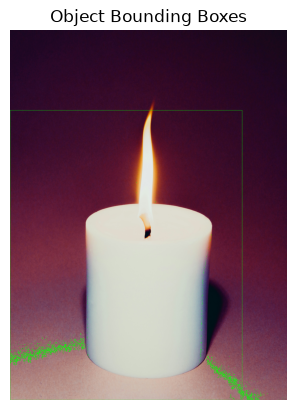

In [16]:
boxed = img.copy()
for contour in contours:
 x, y, w, h = cv2.boundingRect(contour)
 cv2.rectangle(
 boxed,
 (x, y),
 (x + w, y + h),
 (0, 255, 0),
 2
 )
boxed_rgb = cv2.cvtColor(boxed, cv2.COLOR_BGR2RGB)
plt.imshow(boxed_rgb)
plt.title("Object Bounding Boxes")
plt.axis("off")
plt.show()

Write one short line explaining the missing code line and how you fixed it:

The missing code was the required matrix for morphological operations, which I fixed by adding kernel = np.ones((5, 5), np.uint8) to define the 5x5 kernel.
